# Mobile Subscriptions vs Internet Use in Five African Countries
**Question:** Is internet use keeping pace with mobile subscriptions in Ghana, Kenya, Nigeria, Rwanda, and South Africa?

**Data:** World Bank World Development Indicators, 2000-2024. The gap is mobile subscriptions per 100 people minus internet users (%).

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("combined_clean.csv")
print(df.shape)
df.head()

(156, 5)


,Country_Code,Year,Internet_Pct,Mobile_Per100,Gap
0,GHA,1990,0.000000,0.000000,0.000000
1,GHA,1995,0.000348,0.035553,0.035205
2,GHA,1996,0.005650,0.071542,0.065892
3,GHA,1997,0.027500,0.119695,0.092195
4,GHA,1998,0.032200,0.223103,0.190903


In [4]:
df = df[(df["Year"] >= 2000) & (df["Year"] <= 2024)]
print(df.shape)

(124, 5)


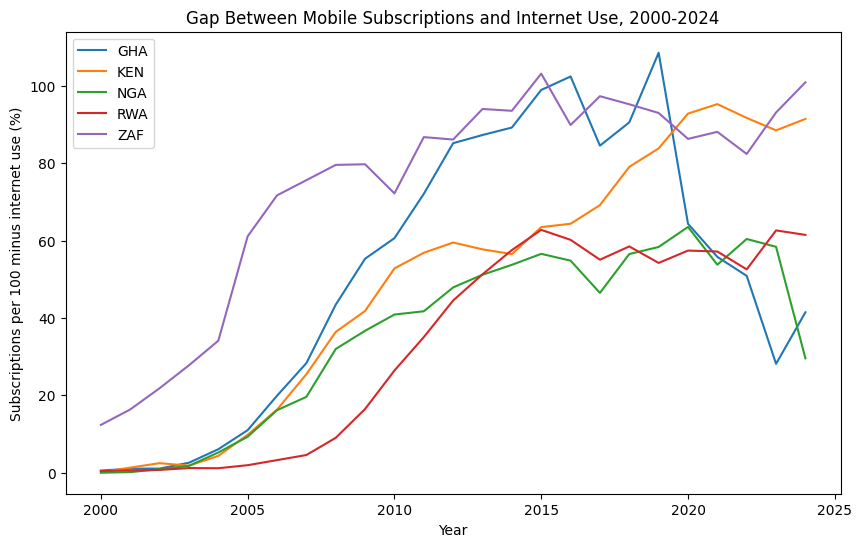

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

for country, group in df.groupby("Country_Code"):
    ax.plot(group["Year"], group["Gap"], label=country)

ax.set_title("Gap Between Mobile Subscriptions and Internet Use, 2000-2024")
ax.set_xlabel("Year")
ax.set_ylabel("Subscriptions per 100 minus internet use (%)")
ax.legend()
plt.show()

In [7]:
peaks = df.loc[df.groupby("Country_Code")["Gap"].idxmax(), ["Country_Code", "Year", "Gap"]]
peaks = peaks.rename(columns={"Year": "Peak_Year", "Gap": "Peak_Gap"})

latest = df[df["Year"] == 2024][["Country_Code", "Gap"]]
latest = latest.rename(columns={"Gap": "Gap_2024"})

summary = peaks.merge(latest, on="Country_Code")
summary["Change_from_peak"] = summary["Gap_2024"] - summary["Peak_Gap"]
summary.round(1)

,Country_Code,Peak_Year,Peak_Gap,Gap_2024,Change_from_peak
0,GHA,2019,108.6,41.5,-67.2
1,KEN,2021,95.3,91.5,-3.8
2,NGA,2020,63.5,29.6,-34.0
3,RWA,2015,62.8,61.5,-1.3
4,ZAF,2015,103.2,101.0,-2.2


In [8]:
fig.savefig("gap_by_country.png", dpi=150, bbox_inches="tight")